In [139]:
import partialRegionBDT
import pickle
import uproot
import os
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve

Function to split input dataset into xgb DMatrices for test and train. Currently sets test size to 1/7 of train size. Needs to split the event weight and label features from the dataset and input them separately into the DMAtrix. This is done via two different methods - manual removal and the sklearn train_test_split function. Needs to output the weights as well, as train_test_split re-orders the lists and the corresponding weights need to be returned as well as the matrices.

In [140]:
def makeTestTrain(inputs,features):
   x = inputs.loc[:, features].values
   y = inputs.loc[:, ['label']].values
   train_input, test_input, train_lbl, test_lbl = train_test_split(x, y, test_size=1/7., random_state=0)
   shortfeat = features[0:len(features)-1]
    
   trainWeights = train_input[:,train_input.shape[1]-1]
   testWeights = test_input[:,test_input.shape[1]-1]
   train_input = np.delete(train_input,train_input.shape[1]-1,1)
   test_input = np.delete(test_input,test_input.shape[1]-1,1)
   dtrain = xgb.DMatrix(train_input,label=train_lbl,feature_names=shortfeat,weight=trainWeights)
   dtest = xgb.DMatrix(test_input,label=test_lbl,feature_names=shortfeat,weight=testWeights)
   return dtrain, dtest, trainWeights, testWeights

This calculates an array of HE weights for a given depth provided by the input 'sfhist'. The overall weight is found by multiplying the weights for each depth, and takes a while to calculate. Because the bin edges aren't fixed, the correct weight is found by iterating over the bins until the correct one is found rather than using a direct list access. This takes a while to calculate when iterating over every depth in every event.  

In [141]:
def getHeDepthWeight(sfhist,heEnergy):
   weights = []
   for energy in heEnergy:
      lastvalue = None
      foundbin = False
      for idx, value in enumerate(sfhist.values()):
         if(sfhist.axis().edges()[idx]>energy):
            weights.append(lastvalue)
            foundbin = True
            break
         lastvalue = value
      if not foundbin:
         weights.append(lastvalue)
   return np.array(weights)

Set the features to pull from the datafile. Can try new trainings by adding/removing features from the lists, but need to make sure that 'EventWeight' is still the last one. Some of the functions are lazy, and assume that the last is event weight when removing it for the BDT training. 

In [142]:
   allfeatures = ["pt","eta","phi","staDR","staPhi","staE","staChi","cscDR","HEDepth_0","HEDepth_1","HEDepth_2","HEDepth_3","HEDepth_4","HEDepth_5","probeCharge","standaloneDEoverE","cscDRbyStation_0","cscDRbyStation_1","cscDRbyStation_2","cscDRbyStation_3","EventWeight"]
   featuresNoHE = ["pt","eta","phi","staDR","staPhi","staE","staChi","cscDR","probeCharge","standaloneDEoverE","cscDRbyStation_0","cscDRbyStation_1","cscDRbyStation_2","cscDRbyStation_3","EventWeight"]
   systWeightFeatures = ["standaloneDEoverE","EventWeight","PUupWeight","PUdownWeight","IDupWeight","IDdownWeight","ISOupWeight","ISOdownWeight","TrigUpWeight","TrigDownWeight","EnBinWeight"]

Load in the input DY file, and append a list of zeroes as a label to indicate that it is background. Also calls the 'getRocRate' function from partialRegionBDT.py to calculate the false positive rate from the previous cut-based approach for use in plotting on the ROC curves. Additionally, pulls the systematic weights (ID,ISO,trig, etc. up/down) which later get used in making inputs to combine.

In [149]:
   inDir="/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/histograms"
   mcFile = uproot.open(str(inDir)+"/ZmmSim.root")
   falsePos = partialRegionBDT.getRocRate(str(inDir)+"/ZmmSim.root")
   events=mcFile["demo"]["partialDisappear"]["sigVariables"]
   mcInputs = events.arrays(allfeatures, library="pd")
   mcSystWeights = events.arrays(systWeightFeatures, library="pd")
   mcLabel = []
   for entry in range(mcInputs.shape[0]):
     mcLabel.append(0)
   mcInputs['label'] = mcLabel 

Load in the signal files. Assumes a certain filename structure (contains "DBrem" and has the mass just before .root). Gets the true positive rate and systematic weights in the same way as the DY loading, and labels them all with 1 to indicate signal.

In [144]:
   sigFiles = []
   sigSystWeights = []
   sigMasses = []
   truePos = []
   scaleFactor = {"0p2":4000,"1p0":40000,"0p4":8000,"0p8":16000,"0p6":12000,"2p0":80000}
   for filename in os.listdir(inDir):
      f = os.path.join(inDir, filename)
      if os.path.isfile(f):
          if "DBrem" in filename:
             apmass = filename.split("_")[-1].split(".")[0]
             for mass, sf in scaleFactor.items():
               if mass in apmass:
                 sigMasses.append(mass)
                 sigEvents=uproot.open(str(inDir)+"/"+filename+":demo/partialDisappear/sigVariables")
                 sigFiles.append(sigEvents.arrays(allfeatures, library="pd"))
                 sigSystWeights.append(sigEvents.arrays(systWeightFeatures,library="pd"))
                 truePos.append(partialRegionBDT.getRocRate(str(inDir)+"/"+filename))
                 massLabel=[]
                 for entry in range(sigFiles[-1].shape[0]):
                   massLabel.append(1)
                 sigFiles[-1]['label']=massLabel
                 sigFiles[-1]['EventWeight']=sf*sigFiles[-1]['EventWeight']

My previous BDT training was done with the initial ~100,000 privately generated endcap muon samples, and now we have an additional ~130,000 endcap muons available. This part loads in the new files as a separate dataframe so that I can test how the BDT performs on completely independent data. In the future we should probably combine these with the original files. TO DO: Combine inputs using these files need a slightly different cross section scaling because of the gen-level filter requiring a muon in the endcap, so I need to run gen xsec analyzer (or manually find the gen matching efficiency) and include it in the total cross section scaling to get the correct expected number of events.  

In [145]:
newGenMCFile = uproot.open(str(inDir)+"/ZmmSim_EndcapMuFilter.root")
newGenfalsePos = partialRegionBDT.getRocRate(str(inDir)+"/ZmmSim_EndcapMuFilter.root")
newGenEvents=newGenMCFile["demo"]["partialDisappear"]["sigVariables"]
newGenMCInputs = newGenEvents.arrays(allfeatures, library="pd")
newGenMCSystWeights = newGenEvents.arrays(systWeightFeatures, library="pd")
newGenMCLabel = []
for entry in range(newGenMCInputs.shape[0]):
  newGenMCLabel.append(0)
newGenMCInputs['label']=newGenMCLabel

This part calculates and applies the hcal depth-by-depth scale factors. The on-edge and off-edge splitting hasn't been added to the analyzer used to make BDT inputs yet, so these scale factors can be fairly large. The scale factor histograms are the ratio of data events in a bin of HE energy over MC events in that bin, so the total event weight is found by multiplying together these ratios across every depth. getHeDepthWeight calculates the array of weights for all events, so the overall event weight is found as the product of all six arrays. To make sure that the weight isn't applied multiple times as the sheet gets used, create a copy of the base one before applying the weight to it each time.
Lastly, I forgot to multiply the standalone delta phi by the probe charge when I made the input trees, so I do it here. Included in this block to make sure that it can't get run twice without reloading and accidentally undo the flip.

**To Check** am I putting a zero or -1 in when the event does not have an expected hit at a particular depth? Did I make sure the weight is one for those depths?

In [150]:
hcalSfHists = []
for depth in range(6):
   hcalSfHists.append(uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/jupyterstuff/hcalSFs.root:hcalSF_depth"+str(depth)))
inputs = []
weightedInputs = []
weightedMcInputs = mcInputs.copy()
reweight=getHeDepthWeight(hcalSfHists[0],weightedMcInputs['HEDepth_'+str(0)])
for depth in range(1,6):
   reweight = reweight*getHeDepthWeight(hcalSfHists[depth],weightedMcInputs['HEDepth_'+str(depth)])
weightedMcInputs['EventWeight']=weightedMcInputs['EventWeight']*reweight
for sigInput in sigFiles:
   inputs.append(pd.concat([mcInputs,sigInput]))
   weightedInputs.append(pd.concat([weightedMcInputs,sigInput]))
for dataset in weightedInputs:
   dataset['staPhi']=dataset['staPhi']*dataset['probeCharge']

The test/train inputs need to be combined dataframes of DY and signal, so create a new array of inputs and put a dataframe of DY events concatenated with each individual signal mass point. Can separate them later based on the 0 or 1 in the label column.

In [147]:
inputs = []
for sigInput in sigFiles:
   inputs.append(pd.concat([mcInputs,sigInput]))

This is the part where we do the bdt training and ROC curve plotting. For each mass, three separate trainings are currently done: a logistic regression with the positive weight set to 1, one with the positive weight set to 0.01, and one with no HE depth information and the positive weight set to 0.01. 

First, a filter is applied to the data to select events with a standalone deltaE over E less than -0.6, so that only probes with standalone muons that have at least 60% less energy are used in order to increase the relative fraction of background events. The efficiency of this cut is calculated for DY and signal (mceff and sigeff) so that the ROC curves can be later re-scaled to the correct fractions. 

We then make a test and train dataset using the makeTestTrain function, which returns the two datasets as well as the event weights corresponding to the re-ordered lists. The logistic regression is performed using the input parameters in 'param', while the rescaled positive weight is done with altparam, which is identical other than the pos_weight. The pos_weight scaled models have the best performance so far, so those models are saved as (A' mass).json. The final training uses altparam, and gives the features list without any HE depth information for the makeTestTrain function to see what impact removing them has.

I then make predictions for the test data samples for the models, and use them to make roc curves which are saved in the curves array along with the selection efficiencies for later plotting.

Lastly, I use the trained BDTs for predicting the entire set of signal and background for input to the combine file maker, as well as predictions of the new independent endcap muon samples. 

['0p4', '0p8', '2p0', '1p0', '0p6', '0p2']
[0]	eval-auc:0.99160	train-auc:0.98948
[1]	eval-auc:0.99602	train-auc:0.99967
[2]	eval-auc:0.99512	train-auc:0.99994
[3]	eval-auc:0.99358	train-auc:0.99999
[4]	eval-auc:0.99450	train-auc:1.00000
[5]	eval-auc:0.99422	train-auc:1.00000
[0]	eval-auc:0.94492	train-auc:0.95810
[1]	eval-auc:0.97967	train-auc:0.98669
[2]	eval-auc:0.99479	train-auc:0.99469
[3]	eval-auc:0.99340	train-auc:0.99727
[4]	eval-auc:0.99279	train-auc:0.99826
[5]	eval-auc:0.98974	train-auc:0.99816
[0]	eval-auc:0.85119	train-auc:0.84620
[1]	eval-auc:0.89302	train-auc:0.89812
[2]	eval-auc:0.93566	train-auc:0.94057
[3]	eval-auc:0.93907	train-auc:0.95162
[4]	eval-auc:0.94311	train-auc:0.95913
[5]	eval-auc:0.95128	train-auc:0.97016
[0]	eval-auc:0.95709	train-auc:0.98988
[1]	eval-auc:0.97467	train-auc:0.99947
[2]	eval-auc:0.97709	train-auc:0.99990
[3]	eval-auc:0.98064	train-auc:0.99995
[4]	eval-auc:0.97989	train-auc:0.99999
[5]	eval-auc:0.97984	train-auc:1.00000
[0]	eval-auc:0.80407	

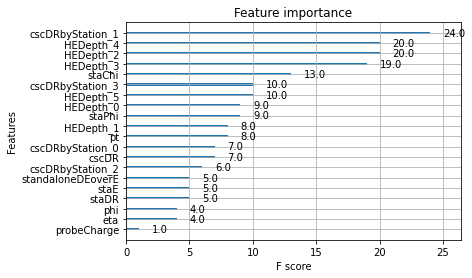

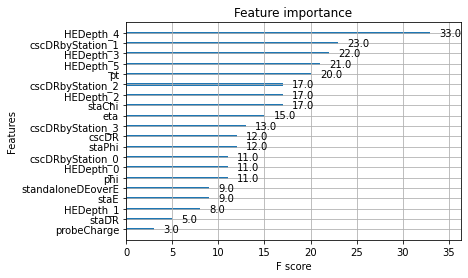

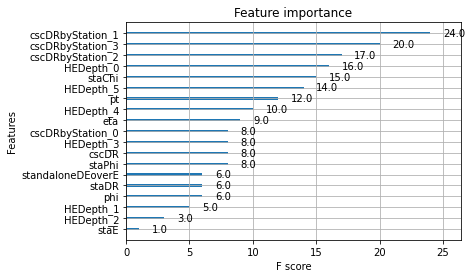

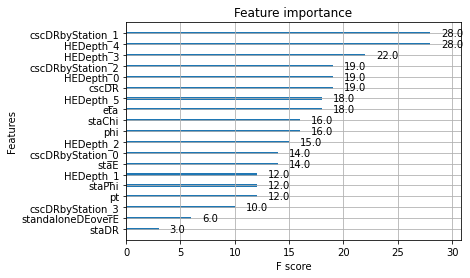

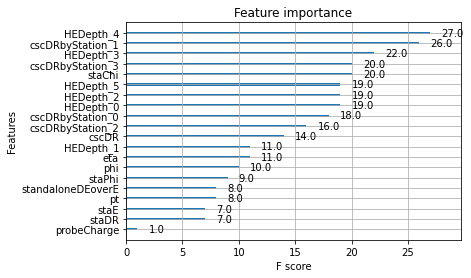

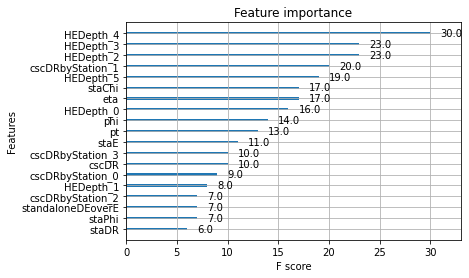

In [151]:
curves = []
importance = []
preds = []
sigPreds = []
newGenPreds = []
print(sigMasses)
for idx, dataset in enumerate(weightedInputs):
  stacut = -0.6
  filter = dataset['standaloneDEoverE']<stacut
  filteredData = dataset[filter]
  mc = dataset[dataset['label']<0.5]
  mceff = mc[mc['standaloneDEoverE']<stacut].shape[0]/mc.shape[0]
  signal = dataset[dataset['label']>0.5]
  sigeff = signal[signal['standaloneDEoverE']<stacut].shape[0]/signal.shape[0]  

  train, test, trainWeight, testWeight = makeTestTrain(filteredData, allfeatures)
  param = {'objective':'binary:logistic','max_depth':8,'eta':1}
  param['nthread'] = 8
  param['eval_metric']='auc'
  altparam = param

  num_round = 6
  evallist = [(test,'eval'),(train,'train')]
  bst = xgb.train(param, train,num_round, evallist)
  pos_weight = 0.01
  altparam['scale_pos_weight']=pos_weight
  altbst = xgb.train(altparam, train, num_round, evallist)
  altbst.save_model(sigMasses[idx]+'.json')

  y_preds = bst.predict(test)
  labels = test.get_label()
  fpr, tpr, thresholds = roc_curve(labels, y_preds,sample_weight=testWeight)
  y_predsAlt = altbst.predict(test)
  labelsalt = test.get_label()
  fpralt, tpralt, thresholdsalt = roc_curve(labelsalt, y_predsAlt,sample_weight=testWeight) 

  hists.append(np.histogram(altbst.predict(train),100))
  mcPred = filteredData[filteredData['label']<0.5].copy()
  mcMatrix = xgb.DMatrix(mcPred.drop(['EventWeight','label'],axis=1))
  preds.append(altbst.predict(mcMatrix))
  newGenFilteredData=newGenMCInputs[newGenMCInputs['standaloneDEoverE']<stacut]
  newGenMCPred = newGenFilteredData[newGenFilteredData['label']<0.5].copy()
  newGenMCMatrix = xgb.DMatrix(newGenMCPred.drop(['EventWeight','label'],axis=1))
  newGenPreds.append(altbst.predict(newGenMCMatrix))
  sigPred = filteredData[filteredData['label']>0.5].copy()
  sigMatrix = xgb.DMatrix(sigPred.drop(['EventWeight','label'],axis=1))
  sigPreds.append(altbst.predict(sigMatrix))

  importance.append(xgb.plot_importance(bst))

  mceffnw = mceff
  sigeffnw = sigeff  
  train, test, trainWeight, testWeight = makeTestTrain(filteredData, featuresNoHE)
  evallist = [(test,'eval'),(train,'train')]
  bst = xgb.train(altparam, train,num_round, evallist)
  y_preds = bst.predict(test)
  
  labels = test.get_label()
  fprnw, tprnw, thresholds = roc_curve(labels, y_preds,sample_weight=testWeight) 

  curves.append([fpr,tpr,fpralt,tpralt,mceff,sigeff,fprnw,tprnw,mceffnw,sigeffnw])

Plot the ROC curves for each of the test BDTs. Multiplies the false and true positive rates by the standalone muon selection efficiency so that the curve is made for the whole dataset to allow for proper comparisons to the cut-based approach.

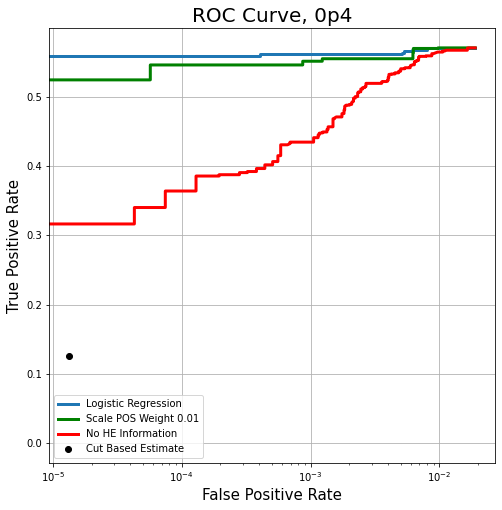

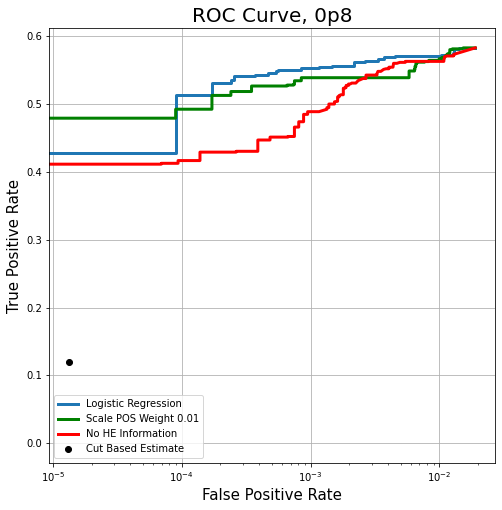

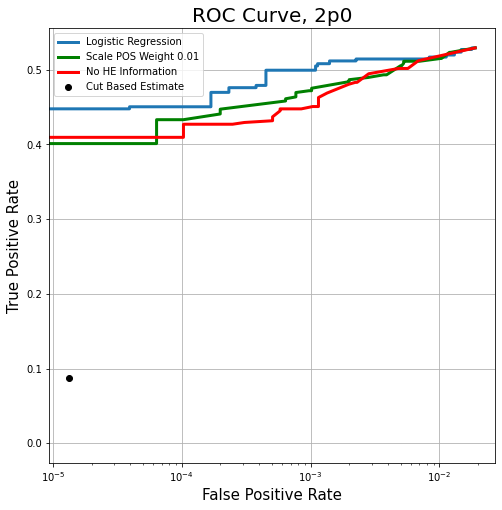

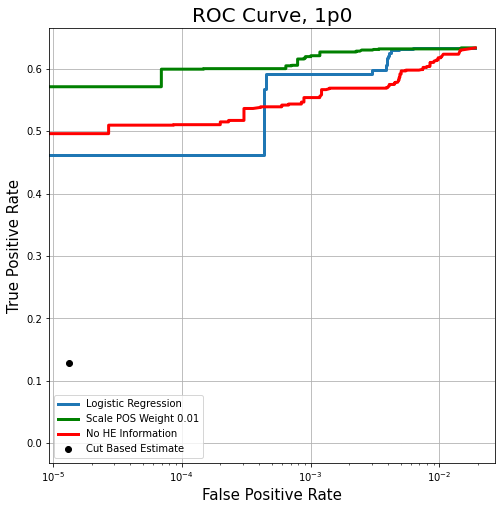

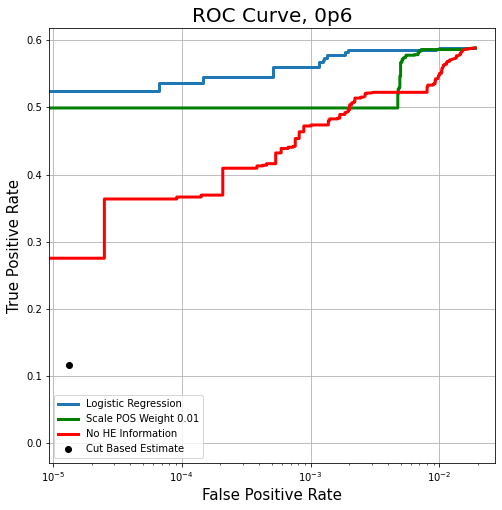

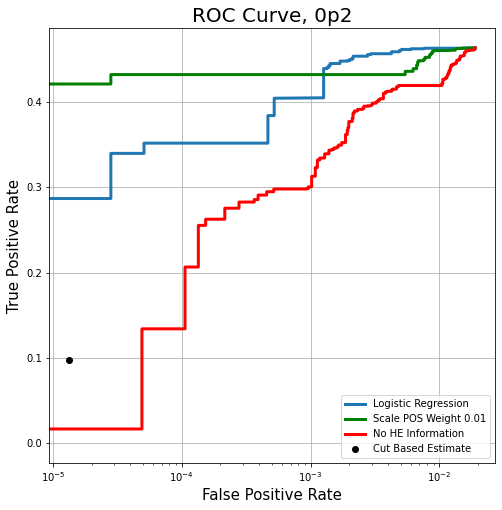

In [152]:
for idx, curve in enumerate(curves):
   fig = plt.figure(figsize = (8,8))
   ax = fig.add_subplot(1,1,1)
   ax.set_xlabel('False Positive Rate', fontsize = 15)
   ax.set_ylabel('True Positive Rate', fontsize = 15)
   ax.set_title('ROC Curve, '+sigMasses[idx], fontsize = 20)
   fpr = curve[0]
   tpr = curve[1]
   fpralt = curve[2]*curve[4]
   tpralt = curve[3]*curve[5]
   fprnoweight = curve[6]*curve[8]
   tprnoweight = curve[7]*curve[9]
   xvar = fpr*curve[4]
   yvar = tpr*curve[5]
   ax.plot(xvar, yvar, '-o',linewidth=3,markersize=0) 
   ax.plot(fpralt,tpralt, '-go',linewidth=3,markersize=0)
   ax.plot(fprnoweight,tprnoweight, '-ro',linewidth=3,markersize=0)
   ax.plot(falsePos,truePos[idx],'ko')
   ax.grid()
   ax.set_xscale('log')
   ax.legend(['Logistic Regression','Scale POS Weight '+str(pos_weight),'No HE Information','Cut Based Estimate'])
   #ax.legend(['Logistic Regression','Scale POS Weight '+str(pos_weight),'Cut Based Estimate'])
#   ax.set_xlim([0.000001,1])
   fig.savefig("partialRegionBDTRocCurve.png")

   ax = importance[idx]
   fig = ax.figure
   fig.savefig("partialBDTImportance.png")

This part makes the dictionaries for my combine input maker. I had trouble making root files with jupyter lab (the python versions are incompatible, so I'd need to switch to a CERN made version of jupyter) so this writes the BDT prediction for each DY and signal point along with the corresponding weights directly to a pickle file, which I load in and then iterate over to fill a histogram in my combine input producer. Maybe more efficient to just used the saved BDTs to re-make the predictions in the other script, but as the file sizes aren't too big and I already have the predictions I did it this way. I also considered just saving the bin edges and counts, but getting the uncertainties correct is a bit of a pain that way.

The file is structured as a list of dictionaries. The first six dictionaries each correspond to a signal mass, and have the mass, standalone muon selection efficiency, DY predictions, signal predictions, and systematic variations for the signal events at that mass.
The final dictionary contains the event weights for the DY samples with each systematic variation, mainly so that the same information isn't repeated in every signal dictionary. 

In [153]:
outputDicts=[]
dySystWeights = newGenMCSystWeights[newGenMCSystWeights['standaloneDEoverE']<stacut]
#dySystWeights = mcSystWeights.copy()
dySystWeights.drop(['standaloneDEoverE'],axis=1)

for idx, mass in enumerate(sigMasses):
    sigSplitSystWeights = sigSystWeights[idx][sigSystWeights[idx]['standaloneDEoverE']<stacut]
    #sigSplitSystWeights = sigSystWeights[idx].copy()
    sigSplitSystWeights.drop(['standaloneDEoverE'],axis=1)
    massDict = {}
    massDict['name']=mass
    massDict['dyEff']=curves[idx][4]
    massDict['sigEff']=curves[idx][5]
    massDict['mcPreds']=newGenPreds[idx]
    massDict['sigPreds']=sigPreds[idx]
    for name, weights in sigSplitSystWeights.iteritems():
        massDict[name]=weights.values
    outputDicts.append(massDict)
dyWeightsDict={}
for name,weights in dySystWeights.iteritems():
    dyWeightsDict[name]=weights.values
outputDicts.append(dyWeightsDict)
pickle.dump(outputDicts, open('bdtPredictions.pkl', 'wb'),protocol=2)